# 워크플로우 패턴 실습: 공지 요청을 라우팅 검사 뒤 나눠 쓰고 허용 목록 바꾸기

**이 노트북에서 할 일**

1. 새 공지 요청 하나와, 종류마다 나눠 쓸 부분을 적은 창구 설정을 만듭니다.
2. 라우팅 검사를 지난 요청만 나눠 쓰기로 보내는 조립 함수로 공지 요청을 처리합니다.
3. 허용 목록 하나만 바꿔 다시 실행하고, 두 실행의 상태와 요청 수를 한 표로 견줍니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델은 `gpt-5.4-mini`이고, 조립 함수 한 번에 요청이 많아야 세 번 나갑니다.
분류 요청 한 번과, 검사를 지났을 때 부분마다 한 번씩입니다.

노트북은 조립 함수를 두 번 부르므로 모델 요청은 여섯 번을 넘지 않습니다.
교재 출력에서는 실행 1이 3번, 실행 2가 1번으로 모두 4번이었습니다.
요금표로 어림한 예상 비용은 0.01달러 아래이고, 청구 금액이 아닙니다.

자료 파일을 읽거나 새 파일을 쓰지 않습니다.
01~03절에서 배운 함수는 같은 폴더의 도구 파일 `workflow_tools.py`에서 가져옵니다.
걸린 시간은 재지 않습니다. 교재 출력을 만든 실행에서는 노트북 전체가 약 5초 만에 끝났습니다.

**기준 버전** — 첫 셀에서 openai 2.29.0과 python-dotenv 1.2.3을 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**실습 범위** — 이 절은 챕터 끝 실습 절이고 30분 안에 끝나는 분량입니다.
강사와 함께 첫 셀부터 차례로 실행하고, 따로 내는 과제는 없습니다.
01~06절에서 쓴 이름과 문법만 씁니다.

실습 폴더 `labs/part5/ch18-workflow-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 초록 상자 공지 요청 글 한 문장 종류 이름은 없음에서 화살표 라벨 조립 함수 serve_notice를 지나 보라 상자 gpt-5.4-mini 앞 단계 분류 요청 한 번과 파란 상자 게이트 자리 check_route 허용 목록 기준값 0.75로 이어지고, 점선 둘이 나뉘어 문제 없음이면 왼쪽 파란 상자 write_sections 갈래 표에서 찾은 부분과 보라 상자 gpt-5.4-mini 뒤 단계 부분 요청을 함께를 지나 노란 상자 상태 완료 안내문 요청 = 1 + 부분 수로 가고, 문제 있음이면 오른쪽 노란 상자 상태 되묻기 되묻기 글 요청 1 부분 요청 없음으로 가는 그림](attachment:07-1-라우팅-검사-뒤-나눠-쓰기.png)

위에서 아래로 읽습니다. 초록 공지 요청 글이 조립 함수 `serve_notice`에 들어가 보라 분류 요청 한 번을 지납니다. 파란 게이트 자리 `check_route`에서 점선이 둘로 나뉩니다. 문제가 없으면 왼쪽 파란 `write_sections`와 보라 부분 요청을 지나 노란 완료 상자로 갑니다. 문제가 있으면 오른쪽 노란 되묻기 상자로 가고, 부분 요청은 하나도 나가지 않습니다.
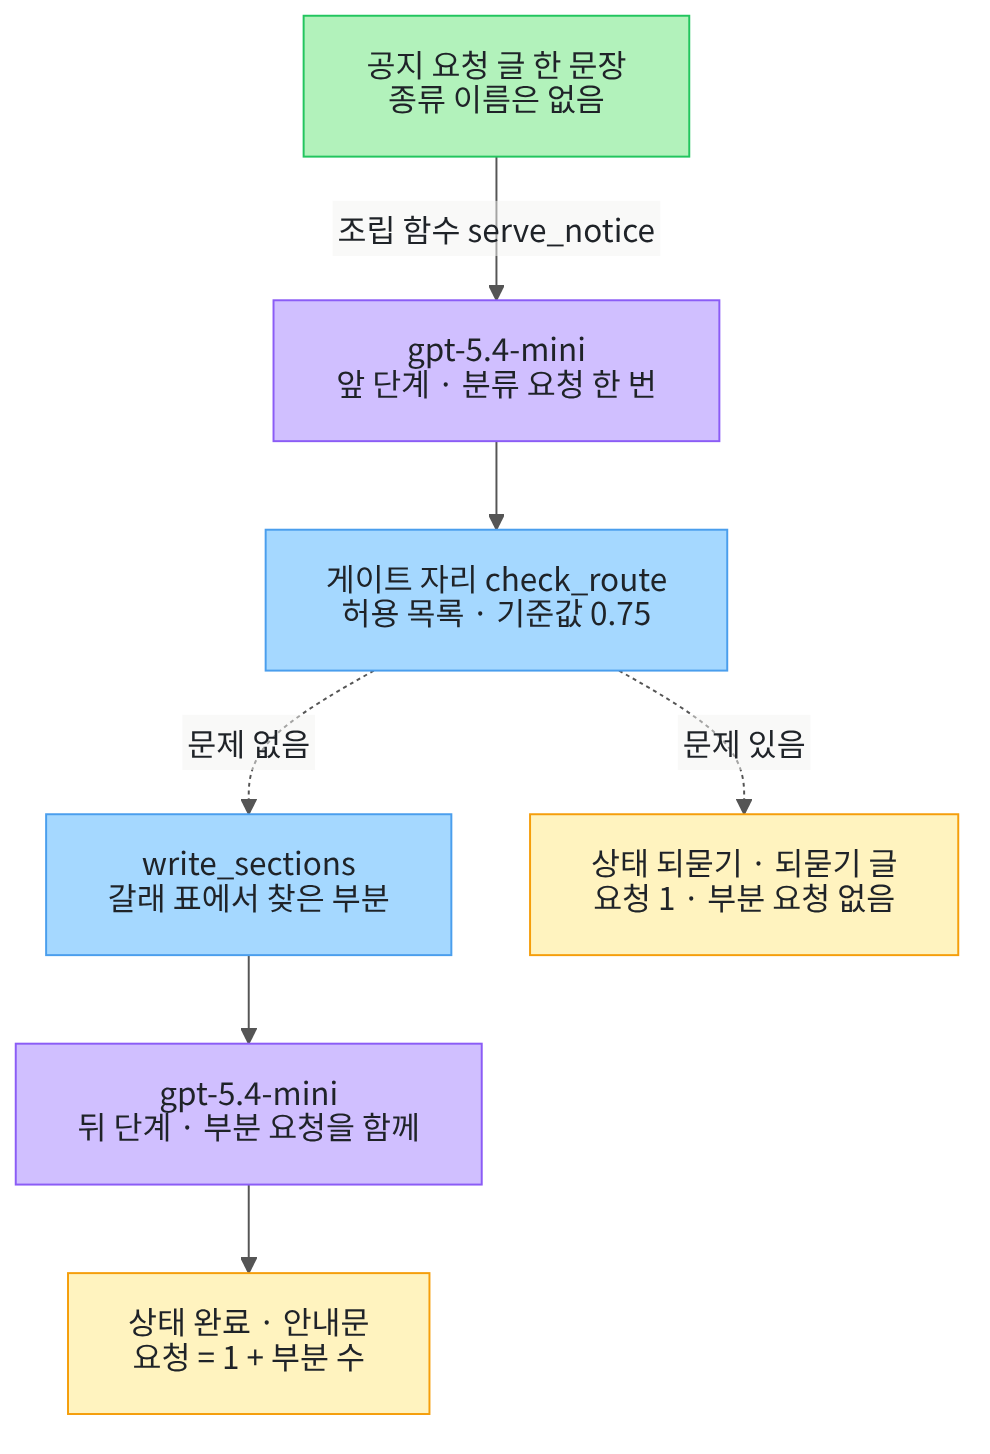

## 1. 준비

이번 절은 이 챕터의 실습입니다.
01~06절에서 쓴 이름과 문법만 쓰고 따로 내는 과제는 없습니다.
첫 셀은 패키지 두 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "openai==2.29.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
openai: 2.29.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `openai: 2.29.0`과 `python-dotenv: 1.2.3`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

앞에서 배운 함수는 `workflow_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
다음 셀은 클라이언트 이름과, 01~03절에서 배운 함수 다섯을 가져옵니다.

In [2]:
# 클라이언트 이름 OpenAI와, 01~03절에서 배운 함수 다섯을 도구 파일 workflow_tools.py에서 가져옵니다
from openai import OpenAI

from workflow_tools import ask_json, build_part_request, check_route, print_records, write_sections

print("01절:", "ask_json", "print_records")
print("02절:", "check_route")
print("03절:", "build_part_request", "write_sections")

01절: ask_json print_records
02절: check_route
03절: build_part_request write_sections


**결과 읽기** — 출력 세 줄이 절마다 가져온 함수 이름입니다.
01절 함수 `ask_json`은 요청 한 번을 보내고 기록 한 줄을 남깁니다.
함수 `print_records`는 그 기록 줄을 줄마다 출력합니다.
02절 함수 `check_route`는 분류를 검사해 문제 목록을 내놓습니다.
03절 함수 `write_sections`는 부분 요청을 함께 보내고, 함수 `build_part_request`는 부분 요청 글을 만듭니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄 `OPENAI_API_KEY 설정 여부: True`로 키를 찾았습니다.
키 값은 출력하지 않습니다.

다음 셀은 01~06절처럼 `client = OpenAI()` 한 줄로 클라이언트를 만듭니다.

In [4]:
# OpenAI 서비스에 요청을 보낼 클라이언트를 하나 만듭니다(키는 앞 셀에서 읽은 환경 변수를 씁니다)
client = OpenAI()
print("클라이언트:", type(client).__name__)

클라이언트: OpenAI


**결과 읽기** — 출력 줄 `클라이언트: OpenAI`로 클라이언트를 만들었습니다.
두 실행의 요청은 모두 이 클라이언트 하나로 보냅니다.

## 2. 상황과 재료

사내 공지 창구 하나를 만든다고 해 봅니다.
직원이 공지 요청 글을 보내면, 창구는 먼저 요청의 종류를 가릅니다.
검사를 지난 요청만 그 종류의 갈래로 보내, 안내문의 부분들을 함께 씁니다.
검사에 걸린 요청은 되묻기 글로 끝냅니다.

다음 셀은 03~06절과 같은 공통 사실을 적습니다.
안내문의 부분들은 이 글에 있는 사실만 씁니다.

In [5]:
# 안내문의 부분들이 함께 쓸 공통 사실을 적습니다(01~06절과 같은 날짜·까닭·등록 방법·문의처)
notice_fact = "2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. "
notice_fact = notice_fact + "비밀번호만으로는 계정을 지키기 어렵기 때문입니다. "
notice_fact = notice_fact + "등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. "
notice_fact = notice_fact + "문의는 help@company.test로 받습니다."
print("공통 사실:")
print(notice_fact)

공통 사실:
2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어렵기 때문입니다. 등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. 문의는 help@company.test로 받습니다.


**결과 읽기** — 라벨 줄 `공통 사실:` 아래 한 줄이 03~06절과 같은 공통 사실입니다.
날짜, 까닭, 등록 방법, 문의처가 한 문장씩 들어 있습니다.
코드 셀 첫 줄 주석은 「01~06절과 같은」이라고 적었지만, 이 공통 사실은 03절부터 썼습니다.
01·02절은 비밀번호 재설정 안내문과 고객 문의라는 다른 과제를 썼습니다.

다음 셀은 이 실습의 새 공지 요청 글을 적습니다.
이 절에서 실행 전에 정한 글이고, 실제 직원이 보낸 글이 아닙니다.

In [6]:
# 이 실습의 새 공지 요청 글을 적습니다(이 절에서 실행 전에 정한 글이고, 실제 직원이 보낸 글이 아닙니다)
notice_request = "전 직원 계정에 2단계 인증을 적용한다는 공지를 올려 주세요."
print("공지 요청:", notice_request)
print("출처:", "이 절에서 실행 전에 적은 글")

공지 요청: 전 직원 계정에 2단계 인증을 적용한다는 공지를 올려 주세요.
출처: 이 절에서 실행 전에 적은 글


**결과 읽기** — 출력 줄 `공지 요청:` 뒤 한 문장이 창구에 넣을 요청 글입니다.
출력 줄 `출처: 이 절에서 실행 전에 적은 글`처럼 요청 글은 실행 전에 적었습니다.
요청 글에는 종류 이름이 없습니다. 종류는 분류 요청이 적습니다.

다음 셀은 분류 지시 글을 적습니다.
02절 분류 지시 글과 모양이 같고, 종류는 06절처럼 보안·인사·회계 셋입니다.

In [7]:
# 분류 단계의 지시 글을 적습니다: 종류 셋과, 하나로 정할 수 없을 때 쓸 이름 「모름」
classify_instructions = "사내 공지 요청을 종류 하나로 가르는 분류 담당입니다. "
classify_instructions = classify_instructions + "종류는 보안, 인사, 회계 가운데 하나로 적습니다. "
classify_instructions = classify_instructions + "하나로 정할 수 없으면 종류를 모름으로 적습니다. "
# 신뢰도는 모델이 스스로 적는 수입니다(재서 얻은 값이 아님)
classify_instructions = classify_instructions + "신뢰도에는 그 종류가 맞다고 보는 정도를 0과 1 사이 수로 적습니다. "
classify_instructions = classify_instructions + '답은 JSON 객체 하나로만 출력합니다: {"종류": "글", "신뢰도": 수}'
print("분류 지시 글:")
print(classify_instructions)

분류 지시 글:
사내 공지 요청을 종류 하나로 가르는 분류 담당입니다. 종류는 보안, 인사, 회계 가운데 하나로 적습니다. 하나로 정할 수 없으면 종류를 모름으로 적습니다. 신뢰도에는 그 종류가 맞다고 보는 정도를 0과 1 사이 수로 적습니다. 답은 JSON 객체 하나로만 출력합니다: {"종류": "글", "신뢰도": 수}


**결과 읽기** — 라벨 줄 `분류 지시 글:` 아래 한 줄이 분류 지시 글입니다.
06절 분류 지시 글과 첫 문장만 다르고, 종류 셋과 답 모양은 같습니다.
신뢰도는 모델이 스스로 적는 수이고, 재서 얻은 값이 아닙니다.

다음 셀은 분류 요청 글을 미리 만들어 봅니다.
요청 머리글 뒤에 공지 요청 글을 붙입니다.
02절에서 본 대로, 형식 `json_object`는 요청 글에 JSON이라는 말이 있어야 합니다.

In [8]:
# 분류 요청 글을 미리 만들어 봅니다: 요청 머리글 + 공지 요청 글(아직 모델을 부르지 않습니다)
# 형식 json_object는 요청 글에 JSON이라는 말이 있어야 해서 머리글에 적어 둡니다
classify_head = "아래 공지 요청에 JSON으로 답하세요.\n요청: "
classify_request = classify_head + notice_request
print("분류 요청 글:")
print(classify_request)

분류 요청 글:
아래 공지 요청에 JSON으로 답하세요.
요청: 전 직원 계정에 2단계 인증을 적용한다는 공지를 올려 주세요.


**결과 읽기** — 라벨 줄 `분류 요청 글:` 아래 두 줄이 분류 요청에 보낼 글입니다.
첫 줄이 요청 머리글이고, 둘째 줄 `요청:` 뒤가 공지 요청 글입니다.
실행 1과 실행 2는 이 글을 그대로 보냅니다.

## 3. 갈래 표와 창구 설정

02절에서는 갈래 표의 값이 갈래의 지시 글이었습니다.
이 실습은 갈래 표의 값을 03절 나눠 쓰기 설정으로 둡니다.
그래서 검사를 지난 요청은 그 종류의 부분들을 함께 보내 안내문을 씁니다.

다음 셀은 부분 하나를 쓰는 작성자의 지시 글과 요청 머리글을 03절 글 그대로 적습니다.

In [9]:
# 부분 하나를 쓰는 작성자의 지시 글과 요청 머리글을 적습니다(03절에서 적은 글 그대로)
section_instructions = "사내 안내문의 한 부분을 쓰는 작성자입니다. "
section_instructions = section_instructions + "공통 사실 가운데 쓸 부분에 맞는 것만 골라 한국어 두 문장으로 씁니다. "
section_instructions = section_instructions + "공통 사실에 없는 날짜·연락처·절차는 지어내지 않습니다. "
section_instructions = section_instructions + '답은 JSON 객체 하나로만 출력합니다: {"부분": "쓸 부분 이름 그대로", "글": "글"}'
section_head = "아래 공통 사실로 안내문의 한 부분을 JSON으로 쓰세요.\n공통 사실: "
print("부분 지시 글:")
print(section_instructions)

부분 지시 글:
사내 안내문의 한 부분을 쓰는 작성자입니다. 공통 사실 가운데 쓸 부분에 맞는 것만 골라 한국어 두 문장으로 씁니다. 공통 사실에 없는 날짜·연락처·절차는 지어내지 않습니다. 답은 JSON 객체 하나로만 출력합니다: {"부분": "쓸 부분 이름 그대로", "글": "글"}


**결과 읽기** — 라벨 줄 `부분 지시 글:` 아래 한 줄이 03절 지시 글과 같은 글입니다.
부분마다 한국어 두 문장으로 쓰고, 공통 사실에 없는 날짜·연락처·절차는 지어내지 않게 합니다.
변수 `section_head`는 03절 요청 머리글이고, 여기에도 JSON이라는 말이 있습니다.

다음 셀은 종류마다 나눠 쓸 부분 목록을 적습니다.
부분 하나에 요청이 한 번 나가므로, 부분 수가 곧 뒤 단계의 요청 수입니다.
부분은 이 절에서 실행 전에 정한 값입니다.

In [10]:
# 종류마다 나눠 쓸 부분 목록을 적습니다(부분 하나에 요청 한 번 — 이 절에서 실행 전에 정한 값)
security_parts = [{"이름": "적용", "담을 내용": "적용 날짜와 대상"}]
security_parts.append({"이름": "등록", "담을 내용": "등록 방법과 문의처 주소"})
hr_parts = [{"이름": "대상", "담을 내용": "대상과 날짜"}, {"이름": "신청", "담을 내용": "신청 방법과 문의처"}]
account_parts = [{"이름": "대상", "담을 내용": "대상과 날짜"}, {"이름": "제출", "담을 내용": "제출 방법과 문의처"}]
print("보안 갈래 부분:")
print(security_parts)
print("부분 수 | 보안", len(security_parts), "| 인사", len(hr_parts), "| 회계", len(account_parts))

보안 갈래 부분:
[{'이름': '적용', '담을 내용': '적용 날짜와 대상'}, {'이름': '등록', '담을 내용': '등록 방법과 문의처 주소'}]
부분 수 | 보안 2 | 인사 2 | 회계 2


**결과 읽기** — 라벨 줄 `보안 갈래 부분:` 아래 목록이 보안 갈래의 부분 둘입니다.
적용 부분은 적용 날짜와 대상, 등록 부분은 등록 방법과 문의처 주소를 맡습니다.
출력 줄 `부분 수 | 보안 2 | 인사 2 | 회계 2`처럼 갈래마다 부분이 둘입니다.
인사·회계 갈래의 부분은 창구가 받을 수 있는 종류를 보이려고 적었습니다.

다음 셀은 종류마다 03절 나눠 쓰기 설정을 만들어 갈래 표 하나에 모읍니다.

In [11]:
# 종류마다 03절 나눠 쓰기 설정(지시 글·요청 머리글·부분)을 만들어 갈래 표 하나에 모읍니다
security_setup = {"지시 글": section_instructions, "요청 머리글": section_head, "부분": security_parts}
hr_setup = {"지시 글": section_instructions, "요청 머리글": section_head, "부분": hr_parts}
account_setup = {"지시 글": section_instructions, "요청 머리글": section_head, "부분": account_parts}
branch_table = {"보안": security_setup, "인사": hr_setup, "회계": account_setup}
branch_kinds = list(branch_table.keys())
security_keys = list(security_setup.keys())
print("갈래 표의 종류:", branch_kinds)
print("보안 갈래의 칸:", security_keys)

갈래 표의 종류: ['보안', '인사', '회계']
보안 갈래의 칸: ['지시 글', '요청 머리글', '부분']


**결과 읽기** — 출력 줄 `갈래 표의 종류: ['보안', '인사', '회계']`로 종류 셋의 갈래를 모았습니다.
출력 줄 `보안 갈래의 칸: ['지시 글', '요청 머리글', '부분']`은 03절 나눠 쓰기 설정과 같은 세 칸입니다.
세 갈래는 지시 글과 요청 머리글이 같고, 부분 목록만 다릅니다.

다음 셀은 보안 갈래 첫 부분의 요청 글을 03절 함수 `build_part_request`로 미리 만듭니다.
03절 함수 `write_sections`도 부분마다 이 함수로 요청 글을 만듭니다.

In [12]:
# 보안 갈래 첫 부분의 요청 글을 03절 함수로 미리 만들어 봅니다(아직 모델을 부르지 않습니다)
first_part_request = build_part_request(section_head, notice_fact, security_parts[0])
print("적용 부분의 요청 글:")
print(first_part_request)

적용 부분의 요청 글:
아래 공통 사실로 안내문의 한 부분을 JSON으로 쓰세요.
공통 사실: 2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어렵기 때문입니다. 등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. 문의는 help@company.test로 받습니다.
쓸 부분: 적용
담을 내용: 적용 날짜와 대상


**결과 읽기** — 라벨 줄 `적용 부분의 요청 글:` 아래 네 줄이 적용 부분 요청에 보낼 글입니다.
첫 두 줄은 머리글과 공통 사실입니다.
셋째 줄 `쓸 부분: 적용`과 넷째 줄 `담을 내용: 적용 날짜와 대상`이 부분마다 다른 자리입니다.

다음 셀은 창구 설정 한 벌을 모읍니다.
02절 라우팅 설정과 같은 여섯 칸이고, 갈래 표의 값만 03절 나눠 쓰기 설정입니다.
허용 목록은 02절처럼 갈래 표의 칸 이름으로 만들고, 기준값도 02절과 같은 0.75입니다.

In [13]:
# 창구 설정 한 벌: 02절 라우팅 설정과 같은 여섯 칸이고, 갈래 표의 값만 03절 나눠 쓰기 설정입니다
desk_setup = {"분류 지시 글": classify_instructions, "요청 머리글": classify_head, "갈래 표": branch_table}
# 허용 목록은 02절처럼 갈래 표의 칸 이름으로 만들어, 갈래가 없는 종류가 끼지 않게 합니다
desk_setup["허용 목록"] = branch_kinds
desk_setup["기준값"] = 0.75
desk_setup["되묻기 글"] = "이 창구에서 바로 쓸 수 없는 공지 요청입니다. 공지 종류와 담당 팀을 적어 다시 보내 주세요."
print("설정 칸 수:", len(desk_setup))
print("허용 목록:", desk_setup["허용 목록"])
print("기준값:", desk_setup["기준값"])

설정 칸 수: 6
허용 목록: ['보안', '인사', '회계']
기준값: 0.75


**결과 읽기** — 출력 줄 `설정 칸 수: 6`으로 02절과 같은 여섯 칸을 모았습니다.
출력 줄 `허용 목록: ['보안', '인사', '회계']`가 실행 1의 허용 목록입니다.
되묻기 글은 검사에 걸린 요청에 보낼 글이고, 되묻기 갈래는 모델을 부르지 않습니다.

## 4. 기록 장치와 조립 함수

실행마다 볼 값은 다섯입니다.
허용 목록, 분류 종류, 상태, 요청 수, 부분 요청 수입니다.
요청 수는 01절에서 정한 대로 기록 줄 수입니다.
부분 요청 수는 뒤 단계에서 받은 부분 답의 수입니다.

다음 셀은 실행 한 번의 값을 실행 요약 딕셔너리 하나로 모으는 함수입니다.

In [14]:
# 기록 장치: 실행 한 번의 허용 목록·분류 종류·상태·요청 수·부분 요청 수를 실행 요약 딕셔너리 하나에 모읍니다
def summarize_run(setup, records, result):
    summary = {"허용 목록": setup["허용 목록"], "종류": result["분류"]["종류"], "상태": result["상태"]}
    # 요청 수는 01절에서 정한 대로 기록 줄 수이고, 부분 요청 수는 받은 부분 답의 수입니다
    summary["요청 수"] = len(records)
    summary["부분 요청 수"] = len(result["부분"])
    return summary

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `summarize_run`은 창구 설정, 기록 목록, 흐름 결과를 받습니다.
흐름 결과의 칸 「부분」은 받은 부분 답의 목록이고, 되묻기로 끝나면 빈 목록입니다.

다음 셀은 이 실습의 기록 장치입니다.
실행 요약 여러 개를 받아 실행마다 한 줄로 출력합니다.

In [15]:
# 기록 장치: 실행 요약을 실행마다 한 줄로 출력합니다
def print_summaries(summaries):
    print("허용 목록 | 종류 | 상태 | 요청 수 | 부분 요청 수")
    for summary in summaries:
        print(summary["허용 목록"], "|", summary["종류"], "|", summary["상태"], "|", summary["요청 수"], "|", summary["부분 요청 수"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_summaries`는 라벨 줄을 먼저 출력하고, 실행 요약 하나마다 한 줄씩 출력합니다.
칸은 01절 기록 줄 출력처럼 세로 막대로 나눕니다.

다음 셀은 이 실습의 조립 함수입니다.
01절 단계 잇기처럼 두 단계를 잇고, 그 사이 게이트 자리에 02절 검사를 둡니다.
앞 단계는 02절 분류 요청이고, 뒤 단계는 03절 나눠 쓰기입니다.
뒤 단계는 분류가 적은 종류로 갈래 표에서 나눠 쓰기 설정을 찾습니다.
함수 안 주석에 어느 절에서 배운 일인지 적었습니다.

In [16]:
# 조립 함수: 01절처럼 두 단계를 잇고 그 사이 게이트 자리에 02절 검사를 둡니다(모델 요청 = 분류 1 + 부분 수, 걸리면 1)
async def serve_notice(client, records, setup, request_text, fact):
    # 앞 단계(02절 라우팅): 요청 머리글과 공지 요청 글로 분류 요청을 한 번 보냅니다
    decision = ask_json(client, records, "분류", setup["분류 지시 글"], setup["요청 머리글"] + request_text)
    # 게이트 자리(01절): 02절 검사에 걸리면 뒤 단계 요청을 하나도 보내지 않고 되묻기로 끝냅니다
    problems = check_route(decision, setup["허용 목록"], setup["기준값"])
    if len(problems) > 0:
        return {"상태": "되묻기", "분류": decision, "문제": problems, "부분": [], "안내문": setup["되묻기 글"]}
    # 뒤 단계(03절 나눠 쓰기): 그 종류 갈래의 설정으로 부분 요청을 함께 보냅니다(요청 = 부분 수)
    written = await write_sections(client, records, setup["갈래 표"][decision["종류"]], fact)
    return {"상태": "완료", "분류": decision, "문제": problems, "부분": written["부분"], "안내문": written["안내문"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `serve_notice`는 클라이언트, 기록 목록, 창구 설정, 공지 요청 글, 공통 사실을 받습니다.
검사에 걸리면 `return`으로 바로 끝나, 부분 요청을 하나도 보내지 않습니다.
그래서 요청 수는 검사를 지나면 1 + 부분 수이고, 걸리면 1입니다.

04절 흐름 함수처럼 `async def` 안에서 동기 함수 `ask_json`과 `await`를 함께 씁니다.
부를 때는 03절처럼 셀 맨 위에서 `await`를 붙입니다.
흐름 결과는 02절 흐름 결과의 칸 「답」 자리에 칸 「안내문」을 두고, 칸 「부분」을 더한 모양입니다.

## 5. 실행 1 · 허용 목록 셋

실행 1은 창구 설정 그대로 공지 요청을 넣습니다.
허용 목록은 보안·인사·회계 셋이고, 기준값은 0.75입니다.

실행 전에 예상해 봅니다.
요청 글이 2단계 인증 공지라, 분류 요청은 종류를 보안으로 적을 것입니다.
보안이 허용 목록에 있고 신뢰도가 기준값 이상이면 검사를 지나 보안 갈래로 갑니다.
그러면 분류 1번과 부분 2번, 모두 세 번 요청할 것입니다.

In [17]:
# 실행 1: 창구 설정 그대로 공지 요청을 넣습니다(모델 요청 = 분류 1 + 부분 수)
records_one = []
result_one = await serve_notice(client, records_one, desk_setup, notice_request, notice_fact)
print("상태:", result_one["상태"])
print("분류:", result_one["분류"])
print("검사가 찾은 문제:", result_one["문제"])
print_records(records_one)

상태: 완료
분류: {'종류': '보안', '신뢰도': 0.99}
검사가 찾은 문제: []
번호 | 단계 | 입력 토큰 | 출력 토큰
1 | 분류 | 138 | 22
2 | 등록 | 196 | 46
3 | 적용 | 194 | 48


**결과 읽기** — 출력 줄 `상태: 완료`와 `검사가 찾은 문제: []`로 검사를 지나 뒤 단계까지 갔습니다.
출력 줄 `분류: {'종류': '보안', '신뢰도': 0.99}`에서 종류는 보안이고, 신뢰도는 기준값보다 높습니다.
라벨 줄 `번호 | 단계 | 입력 토큰 | 출력 토큰` 아래 세 줄이 기록이고, 요청은 예상대로 세 번이었습니다.
첫 줄 `1 | 분류 | 138 | 22`가 분류 요청이고, 나머지 두 줄이 적용·등록 부분 요청입니다.

부분 두 줄의 차례는 응답이 도착한 차례라 실행마다 달라질 수 있습니다.
교재 출력에서는 등록 줄이 먼저였고, 새 커널로 한 번 더 실행했을 때는 적용 줄이 먼저였습니다.
부분 요청의 출력 토큰도 실행마다 달라질 수 있어 결론에 쓰지 않습니다.
노트북 밖에서 같은 두 실행을 다섯 번 보냈을 때도 분류와 요청 수는 다섯 번 모두 같았습니다.

In [18]:
# 실행 1에서 받은 부분 답의 칸 「부분」 차례와, 넣은 차례로 이은 안내문을 봅니다(모델 요청 없음)
part_order = []
for answer in result_one["부분"]:
    part_order.append(answer["부분"])
print("받은 부분 차례:", part_order)
print("안내문:")
print(result_one["안내문"])

받은 부분 차례: ['적용', '등록']
안내문:
2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 적용 대상은 전 직원 계정입니다.
등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. 문의는 help@company.test로 보내 주시기 바랍니다.



**결과 읽기** — 출력 줄 `받은 부분 차례: ['적용', '등록']`은 넣은 차례 그대로입니다.
03절에서 본 것처럼, 함께 보낸 요청의 답 목록은 기록 줄 차례와 달리 넣은 차례를 지킵니다.
라벨 줄 `안내문:` 아래 두 줄이 부분 답의 글을 넣은 차례로 이은 안내문입니다.

안내문 글은 실행마다 달라질 수 있어 이 실습의 결론에 쓰지 않습니다.
검사는 무엇을 받을지만 정하고, 안내문이 맞게 쓰였는지는 보지 않습니다.

다음 셀은 실행 1의 값을 실행 요약으로 모아 한 줄로 봅니다.

In [19]:
# 실행 1의 요약을 한 줄로 보고, 부분 요청 수가 보안 갈래의 부분 수와 같은지 봅니다(모델 요청 없음)
summary_one = summarize_run(desk_setup, records_one, result_one)
print_summaries([summary_one])
print("보안 갈래의 부분 수:", len(security_parts))
print("부분 요청 수가 부분 수와 같은가:", summary_one["부분 요청 수"] == len(security_parts))

허용 목록 | 종류 | 상태 | 요청 수 | 부분 요청 수
['보안', '인사', '회계'] | 보안 | 완료 | 3 | 2
보안 갈래의 부분 수: 2
부분 요청 수가 부분 수와 같은가: True


**결과 읽기** — 라벨 줄 `허용 목록 | 종류 | 상태 | 요청 수 | 부분 요청 수` 아래 한 줄이 실행 1의 요약입니다.
출력 줄 `['보안', '인사', '회계'] | 보안 | 완료 | 3 | 2`를 봅니다.
출력 줄 `부분 요청 수가 부분 수와 같은가: True`로 부분 요청 수가 보안 갈래의 부분 수와 같습니다.
요청 수 3은 분류 1번과 부분 2번을 더한 수입니다.

## 6. 실행 2 · 보안을 뺀 허용 목록

바꿀 값은 허용 목록 하나입니다. 보안을 빼고 인사·회계만 남깁니다.
이번 주 보안 공지는 보안팀이 직접 쓰기로 했다고 정한 설정입니다.
공지 요청 글과 분류 지시 글, 갈래 표, 기준값, 조립 함수는 실행 1과 같습니다.
다음 셀은 05절처럼 창구 설정을 `copy()`로 복사해 허용 목록 한 칸만 바꿉니다.

In [20]:
# 실행 2의 설정: 바꿀 값은 허용 목록 하나입니다. 창구 설정을 복사해 보안을 뺀 목록으로 바꿉니다
narrow_setup = desk_setup.copy()
narrow_setup["허용 목록"] = ["인사", "회계"]
# 여섯 칸 가운데 두 설정의 값이 같은 칸만 모아, 바뀐 칸이 허용 목록 하나인지 봅니다
same_keys = []
for key in list(desk_setup.keys()):
    if narrow_setup[key] == desk_setup[key]:
        same_keys.append(key)
print("실행 2 허용 목록:", narrow_setup["허용 목록"])
print("그대로인 칸:", same_keys)

실행 2 허용 목록: ['인사', '회계']
그대로인 칸: ['분류 지시 글', '요청 머리글', '갈래 표', '기준값', '되묻기 글']


**결과 읽기** — 출력 줄 `실행 2 허용 목록: ['인사', '회계']`가 바꾼 값입니다.
출력 줄 `그대로인 칸:` 뒤 목록에 허용 목록을 뺀 다섯 칸이 있습니다.
복사한 딕셔너리의 한 칸에 새 목록을 넣었으므로, 실행 1의 허용 목록은 그대로 남습니다.

실행 전에 예상해 봅니다.
분류 요청 글은 실행 1과 글자까지 같으니, 분류는 이번에도 보안일 것입니다.
보안이 허용 목록에 없으니 검사에 걸려 되묻기로 끝날 것입니다.
그러면 부분 요청은 나가지 않고, 요청은 분류 한 번뿐일 것입니다.

In [21]:
# 실행 2: 같은 공지 요청을 바꾼 설정으로 넣습니다(모델 요청 = 분류 1, 검사에 걸리면 부분 요청 없음)
records_two = []
result_two = await serve_notice(client, records_two, narrow_setup, notice_request, notice_fact)
print("상태:", result_two["상태"])
print("분류:", result_two["분류"])
print("검사가 찾은 문제:", result_two["문제"])
print("요청자에게 보낼 글:", result_two["안내문"])
print_records(records_two)

상태: 되묻기
분류: {'종류': '보안', '신뢰도': 0.99}
검사가 찾은 문제: ['허용 목록에 없는 종류']
요청자에게 보낼 글: 이 창구에서 바로 쓸 수 없는 공지 요청입니다. 공지 종류와 담당 팀을 적어 다시 보내 주세요.
번호 | 단계 | 입력 토큰 | 출력 토큰
1 | 분류 | 138 | 22


**결과 읽기** — 출력 줄 `상태: 되묻기`와 `검사가 찾은 문제: ['허용 목록에 없는 종류']`로 검사에 걸렸습니다.
출력 줄 `분류: {'종류': '보안', '신뢰도': 0.99}`는 실행 1과 같은 분류입니다.
라벨 줄 아래 기록은 `1 | 분류 | 138 | 22` 한 줄뿐이고, 부분 요청은 나가지 않았습니다.
출력 줄 `요청자에게 보낼 글:` 뒤가 창구 설정의 되묻기 글입니다. 예상과 맞았습니다.

새 커널로 한 번 더 실행했을 때도 이 셀의 출력은 같았습니다.
노트북 밖에서 같은 두 실행을 다섯 번 보냈을 때도 분류는 모두 보안 0.99였고, 실행 2는 모두 되묻기였습니다.

## 7. 두 실행 견주기

다음 셀은 두 실행의 요약을 한 표로 견주고, 두 실행의 분류 종류가 같은지 봅니다.

In [22]:
# 두 실행의 요약을 한 표로 견주고, 두 실행의 분류 종류가 같은지 봅니다(모델 요청 없음)
summary_two = summarize_run(narrow_setup, records_two, result_two)
print_summaries([summary_one, summary_two])
print("두 실행의 분류 종류가 같은가:", result_one["분류"]["종류"] == result_two["분류"]["종류"])

허용 목록 | 종류 | 상태 | 요청 수 | 부분 요청 수
['보안', '인사', '회계'] | 보안 | 완료 | 3 | 2
['인사', '회계'] | 보안 | 되묻기 | 1 | 0
두 실행의 분류 종류가 같은가: True


**결과 읽기** — 라벨 줄 아래 두 줄을 견줍니다.
출력 줄 `['보안', '인사', '회계'] | 보안 | 완료 | 3 | 2`가 실행 1입니다.
출력 줄 `['인사', '회계'] | 보안 | 되묻기 | 1 | 0`이 실행 2입니다.
출력 줄 `두 실행의 분류 종류가 같은가: True`로 모델이 쓴 종류는 같았습니다.
같은 분류가 허용 목록 하나 때문에 다른 갈래로 갔습니다.

다음 셀은 두 실행의 첫 기록 줄을 나란히 봅니다.
기록 첫 줄 `[0]`은 늘 분류 요청의 줄이고, 두 실행의 분류 요청 글은 글자까지 같습니다.

In [23]:
# 두 실행의 첫 기록 줄(분류 요청)을 나란히 봅니다: 요청 글이 같으면 입력 토큰도 같습니다
first_one = records_one[0]
first_two = records_two[0]
print("첫 줄 단계 | 실행 1", first_one["단계"], "| 실행 2", first_two["단계"])
print("분류 요청 입력 토큰 | 실행 1", first_one["입력 토큰"], "| 실행 2", first_two["입력 토큰"])
print("입력 토큰이 같은가:", first_one["입력 토큰"] == first_two["입력 토큰"])

첫 줄 단계 | 실행 1 분류 | 실행 2 분류
분류 요청 입력 토큰 | 실행 1 138 | 실행 2 138
입력 토큰이 같은가: True


**결과 읽기** — 출력 줄 `첫 줄 단계 | 실행 1 분류 | 실행 2 분류`로 두 첫 줄 모두 분류 요청입니다.
출력 줄 `분류 요청 입력 토큰 | 실행 1 138 | 실행 2 138`과 `입력 토큰이 같은가: True`를 봅니다.
허용 목록은 모델에게 보내는 글에 들어가지 않으므로, 분류 요청은 두 실행이 같았습니다.

다음 셀은 실행 2가 보내지 않은 요청 수를 셉니다.

In [24]:
# 실행 2가 보내지 않은 요청 수를 셉니다: 실행 1의 기록 줄 수에서 실행 2의 기록 줄 수를 뺍니다
saved_count = len(records_one) - len(records_two)
print("줄어든 요청 수:", saved_count)
print("보안 갈래의 부분 수와 같은가:", saved_count == len(security_parts))

줄어든 요청 수: 2
보안 갈래의 부분 수와 같은가: True


**결과 읽기** — 출력 줄 `줄어든 요청 수: 2`와 `보안 갈래의 부분 수와 같은가: True`를 봅니다.
실행 2는 검사에 걸려 보안 갈래의 부분 요청 둘을 보내지 않았습니다.
검사를 부분 요청 앞에 두었기 때문에, 받지 않을 요청에 뒤 단계 요청이 나가지 않았습니다.

## 정리

1. 02절 라우팅 검사와 03절 나눠 쓰기를 01절 단계 잇기처럼 한 조립 함수로 이어, 공지 요청 하나를 처리했습니다.
2. 검사를 지난 실행 1은 분류 1번과 부분 2번으로 요청이 3번이었고, 안내문을 받았습니다.
3. 허용 목록에서 보안만 빼자 같은 분류가 검사에 걸려 되묻기로 끝났고, 부분 요청 2번이 나가지 않았습니다.

이 절로 Ch 18이 끝납니다.
Ch 19에서는 함수를 도구로 만들고, 모델이 도구 설명을 보고 고르게 합니다.